# Regressionsanalyse

[Vorlesungsaufzeichnung Regression (VL 19)](https://media.hhu.de/channel/video/data-science-vl-19-regression-2025/df00fcd2038eb5b297b77bb5369bb960/167)
[Regression und Regularisierung (VL 20, ohne Ton)](https://media.hhu.de/channel/video/data-science-vl-20-regression-und-regularisierung-2025/f308330baee63f83093c7d4068502840/167)

Wenn man einen Datensatz hinreichend aufbereitet hat (fehlende Daten ersetzt, geeignet reskaliert, neue Features definiert), kann man sich an eine Regressionsanalyse wagen. Bei einer Regression geht es darum, den Zusammenhang zwischen zwei Variablen zu beschreiben. Dabei soll eine Variable als abhängig von der anderen beschrieben werden, explizit durch die Angabe eines funktionalen Zusammenhangs, d.h. einer mathematischen Abbildung, die aus den Werten der einen Variable die Werte der anderen berechnet - näherungsweise.

Ein Beispiel, bevor wir die Vokabeln festlegen. Beim Iris-Datensatz vermuten wir einen Zusammenhang zwischen der Länge und der Breite eines Blütenblatts: Längere Blätter dürften auch breiter sein. Wir schauen uns die Punktwolke an und legen — zunächst ganz nach Augenmaß — eine Gerade hinein.


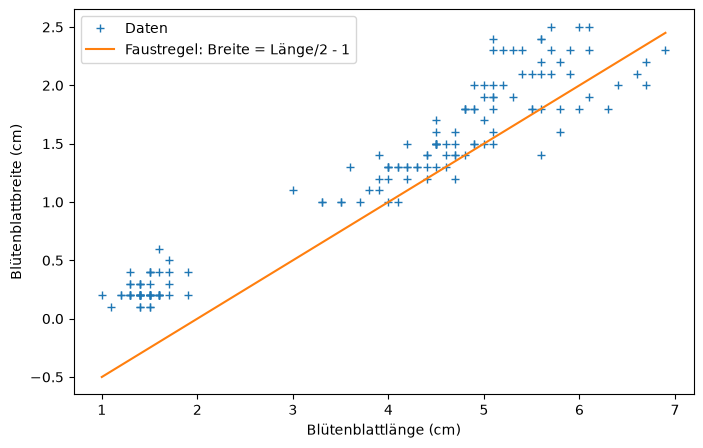

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn import datasets

iris_daten = datasets.load_iris().data
petal_length, petal_width = iris_daten[:, 2], iris_daten[:, 3]

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(petal_length, petal_width, "+", label="Daten")
gerade = np.linspace(petal_length.min(), petal_length.max(), 2)
ax.plot(gerade, 0.5 * gerade - 1, label="Faustregel: Breite = Länge/2 - 1")
ax.set_xlabel("Blütenblattlänge (cm)")
ax.set_ylabel("Blütenblattbreite (cm)")
ax.legend()
plt.show()

Abgelesen haben wir die Faustregel

```python
predicted_petal_width = petal_length * 0.5 - 1
```

und damit stecken bereits alle Bestandteile einer Regression in dem Beispiel:

1. Es gibt eine **Funktion**, die aus der Einflussgröße die Zielgröße berechnet — hier $x \mapsto 0{,}5\,x - 1$.
2. Die Funktion hat **Parameter**, hier die Zahlen $0{,}5$ und $-1$, und die haben wir aus den Daten gewonnen, nicht aus der Theorie.
3. Die Vorhersage ist **nicht exakt**. Für jede einzelne Blüte bleibt ein Rest, und über den müssen wir Buch führen.

Der dritte Punkt ist der Grund, warum eine Regression nicht einfach eine Funktion ist. Und Punkt 2 wirft sofort die Frage auf, ob $0{,}5$ und $-1$ denn die besten Zahlen sind — der Rest des Kapitels beantwortet sie. (Vorweg: Sind sie nicht. Die Methode der kleinsten Quadrate findet $0{,}416$ und $-0{,}363$ und drückt den mittleren quadratischen Fehler von $0{,}167$ auf $0{,}042$.)

Ein **Regressionsmodell** besteht aus:

* **Regressoren** $x_i$, das ist eine ($k$-variate) 'unabhängige' Variable, die *Einflussgröße* (hier ist $k$ die Anzahl der Regressoren, nicht die Anzahl der Cluster wie bei k-Means)
* **Regressand** $y_i$, das ist eine (univariate) 'abhängige' Variable, die *Zielgröße*
* **Parametern** $\beta_1,\dots,\beta_k$
* **Störgrößen** $\epsilon_i$
* $Y_i = f(X_i, \beta) + \epsilon_i$

Für konkrete Daten $(x_i,y_i)$ nennt man $y_i - f(x_i, \beta)$ für ein gegebenes Regressionsmodell auch **das $i$-te Residuum**.

Dafür lohnt sich eine feste Schreibweise. Eine Stichprobe besteht aus **Instanzen** $x_1,\dots,x_N$ und den zugehörigen Werten der Zielgröße $y_1,\dots,y_N$, die im maschinellen Lernen **Label** heißen. Ist der Regressor mehrdimensional, so schreiben wir $x_{ij}$ für den Wert des $j$-ten Merkmals bei der $i$-ten Instanz — der erste Index zählt die Zeilen der Tabelle, der zweite die Spalten. Die **Vorhersage** des Modells ist

$$
y_i^{pred} := f(x_i; \beta),
$$

sie hängt also von den geschätzten Parametern ab und ändert sich mit ihnen. Die Residuen sind dann genau die Differenzen $y_i - y_i^{pred}$, und damit sind sie das, was von den Störgrößen sichtbar wird: Die Störgröße $\epsilon$ ist eine Zufallsvariable, die wir nie beobachten; die Residuen sind ihre Instanzen, sobald wir uns auf ein $\beta$ festgelegt haben. Deshalb prüft man ein Regressionsmodell, indem man sich die Residuen ansieht — sie sollten aussehen wie eine Stichprobe aus der Verteilung, die man für $\epsilon$ angenommen hat.

Eine Regressionsanalyse besteht darin, ein Regressionsmodell aufzustellen und dann die Funktion $f$ zu schätzen, die am besten zu den Daten passt, d.h. die kleinsten Residuen hat.

Bestimmte Regressionsverfahren unterscheiden sich in der Art der zulässigen Funktion $f$.
Bei der linearen Regression ist $f$ eine Funktion, die in den Parametern $\beta$ linear ist.

```{admonition} Beispiel
Der Einfachheit halber sei $k=1$, d.h. $X_i$ eine univariate Variable.
Wenn wir für $f$ die Klasse der konstanten Funktionen wählen, dann ist $f(X_i,\beta) = \beta_1$
und wir suchen das $\beta_1$, sodass $Y_i = \beta_1 + \epsilon_i$, also ein $\beta_1$, welches für alle Werte $y_i$ den Abstand $d(\beta_1, y_i) = y_i - \beta_1$ minimiert.
Das ist der Fall für $\texttt{mse}(y,\beta_1) = \frac{1}{n} \sum_{i=1}^n (y_i - \beta_1)^2$ minimal, d.h. $\beta_1 = \texttt{mean}(y)$.
```

```{admonition} Beispiel
Man kann k-Means als Regressionsverfahren sehen: die Parameter $\beta$ beschreiben die Orte der Zentroide und die Funktion $f$ ist die Auswahl einer Klasse in Abhängigkeit vom nächstgelegenen Zentroid. Das konkrete k-Means-Verfahren ist die Suche nach einer Näherung für optimale Parameter $\beta$.

Bei k-Means werden die Störgrößen normalverteilt ohne Korrelation angenommen.
```

```{admonition} Beispiel
Jedes Klassifikationsverfahren ist eine Regression, wobei die abhängige Variable die Klasse ist, die Regressoren alle Daten, die zur Klassifikation verwendet werden. Wörtlich nehmen sollte man das aber nicht: Eine lineare Regression direkt auf Klassennummern $0, 1, 2, \dots$ ist kein sinnvoller Klassifikator, denn die Nummern sind keine Werte auf einer Skala. Klassifikationsverfahren wie die *logistische Regression* schalten deshalb eine Link-Funktion dazwischen, die den Wertebereich auf Klassenwahrscheinlichkeiten abbildet.
```

## Kleinste Quadrate

```{admonition} Definition
Wenn man in einem Regressionsmodell die **Residuenquadratsumme** $\sum_{i=1}^N {\left(Y_i - f(X_i,\beta)\right)}^2$ minimiert, spricht man von einem Schätzwert für $\beta$, der als **kleinste-Quadrate-Schätzer** bekannt ist.
```

Der kleinste-Quadrate-Schätzer ist ein Maximum-Likelihood-Schätzer, wenn man die Störgrößen als normalverteilt annimmt (das Modell dazu steht am Ende des Abschnitts *Lineare Regression*).

```{admonition} Beispiel
Wenn wir zu Punkten $(x_i,y_i)$ in der Ebene eine Gerade berechnen,
die den gemeinsamen Abstand zu allen Punkten minimiert (eine sogenannte Ausgleichsgerade),
so ist dies genau eine Regression mit $f(x, \beta) = \beta_0 + \beta_1 x$.
Die Regressionsgleichung $Y_i = f(X_i, \beta)$ wird zur Geradengleichung
$y_i = \beta_0 + \beta_1 x_i$
wobei $\beta_0$ der y-Achsenabschnitt (bei $x_i=0$) und $\beta_1$ die Steigung der Geraden ist.

Die kleinste-Quadrate-Methode ist nun, $\beta_0$ und $\beta_1$ so zu schätzen,
dass $\sum_{i=1}^N {\left(y_i - \beta_1x_i - \beta_0  \right)}^2$ minimiert wird.

Wenn $\beta_0=0$ ist haben wir ein lösbares Minimierungsproblem.
Wir leiten nach $\beta_1$ ab und suchen Nullstellen:

$$
\begin{aligned}
0 &= \sum_{i=1}^N 2{\left(y_i - \beta_1 x_i  \right)}{\left(- x_i  \right)} \\
  &= \sum_{i=1}^N 2 \left( \beta_1 x_i^2 - y_i x_i \right) \\
  &= 2\left(\beta_1 \sum_{i=1}^N x_i^2 - \sum_{i=1}^N x_iy_i \right)
\end{aligned}
$$

also ist $\beta_1 = \dfrac{\sum_{i=1}^N x_iy_i}{\sum_{i=1}^N x_i^2}$.
```

Im Allgemeinen lässt sich $\beta_0$ berechnen mit der Formel

$$
\beta_0 = \texttt{mean}(y) - \beta_1\texttt{mean}(x).
$$

Um also zunächst $\beta_1$ im Allgemeinen zu bestimmen, verschiebt man die Daten um die Mittelwerte, also ersetzt $x_i$ durch $x_i' = x_i - \texttt{mean}(x)$ und $y_i$ durch $y_i' = y_i - \texttt{mean}(y)$. Damit erhält man die Formel

$$
\beta_1 = \dfrac{\sum_{i=1}^N (x_i - \texttt{mean}(x))(y_i - \texttt{mean}(y))}{\sum_{i=1}^N (x_i - \texttt{mean}(x))^2}
$$

Teilt man Zähler und Nenner durch $N$, stehen dort zwei Größen, die wir schon kennen: oben die empirische Kovarianz von $x$ und $y$, unten die empirische Varianz von $x$ (beide in der $n$-Version, siehe die Bemerkung *Für Daten* im Kapitel [Kovarianz](kovarianz.md)). Die Steigung der Ausgleichsgeraden ist also

$$
\beta_1 = \dfrac{\operatorname{Cov}(x,y)}{\sigma^2(x)}, \qquad \beta_0 = \texttt{mean}(y) - \beta_1\,\texttt{mean}(x).
$$

Das ist die Form, in der man die Rechnung am schnellsten von Hand durchführt, und sie sagt auch etwas: Die Steigung ist die Kovarianz, normiert auf die Streuung des Regressors. Vergleicht man mit dem Korrelationskoeffizienten $\rho = \operatorname{Cov}(x,y) / (\sigma(x)\sigma(y))$ aus dem Kapitel [Kovarianz](kovarianz.md), so ist $\beta_1 = \rho\,\sigma(y)/\sigma(x)$ — Korrelation und Regressionssteigung unterscheiden sich nur um das Verhältnis der beiden Standardabweichungen.

```{admonition} Beispiel
Für die vier Punkte $x = (-2, -1, 1, 2)$ und $y = (-3, -1, 1, 3)$ sind beide Mittelwerte $0$, also

$$
\sigma^2(x) = \tfrac14\left( 4 + 1 + 1 + 4 \right) = 2{,}5, \qquad
\operatorname{Cov}(x,y) = \tfrac14\left( 6 + 1 + 1 + 6 \right) = 3{,}5,
$$

und damit $\beta_1 = 3{,}5 / 2{,}5 = 1{,}4$ und $\beta_0 = 0 - 1{,}4 \cdot 0 = 0$. Die Ausgleichsgerade ist $y = 1{,}4\,x$.
```


In [2]:
import numpy as np
np.random.seed(1234)

# generate synthetic data:
x = np.linspace(-2, 8)
y = x**2 + 3*x - 7 + np.random.uniform(-3, 3, size=x.shape)

# compute estimate from before:
x_centered = x - np.mean(x)
y_centered = y - np.mean(y)
beta_1 = ( x_centered.T @ y_centered ) / sum(np.square(x_centered))
beta_0 = np.mean(y) - beta_1*np.mean(x)
# dieselbe Zahl als Kovarianz durch Varianz (ddof=0: n-Version, wie np.var):
assert np.isclose(beta_1, np.cov(x, y, ddof=0)[0, 1] / np.var(x))
print("line equation is y = %f*x + %f" % (beta_1, beta_0))


line equation is y = 8.912806*x + -6.929693


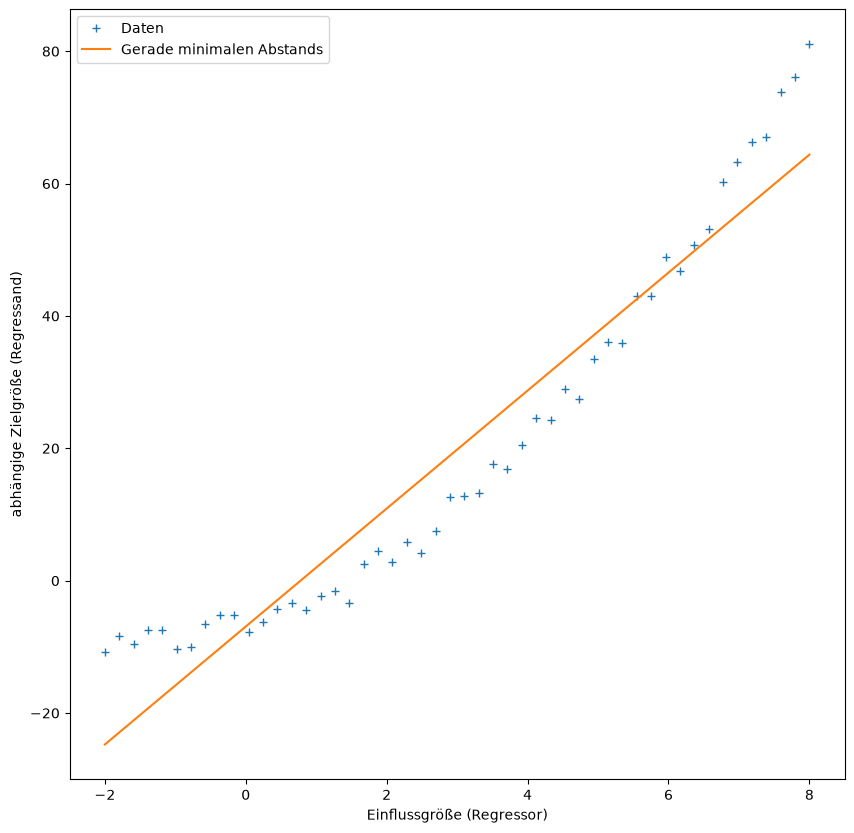

In [3]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10,10))
ax.plot(x, y, "+", label="Daten")
ax.plot(x, beta_0 + x*beta_1, label="Gerade minimalen Abstands")
ax.set_xlabel("Einflussgröße (Regressor)")
ax.set_ylabel("abhängige Zielgröße (Regressand)")
ax.legend()
plt.show()

Die Methode kleinster Quadrate lässt sich auch direkt mit Scipy nutzen (also muss man sich die Formeln oder die Herleitung nicht merken):

In [4]:
from scipy.optimize import curve_fit

# define function class for regression (linear):
def f(x, beta_0, beta_1):
    return beta_1*x + beta_0

# perform regression analysis:
parameters, covariance_matrix = curve_fit(f, x, y)
assert np.all(np.isclose((beta_0, beta_1), parameters))

Aus der Dokumentation von Scipy:

`scipy.optimize.curve_fit`
>
> Use non-linear least squares to fit a function, f, to data.
> 
> Assumes ydata = f(xdata, *params) + eps.

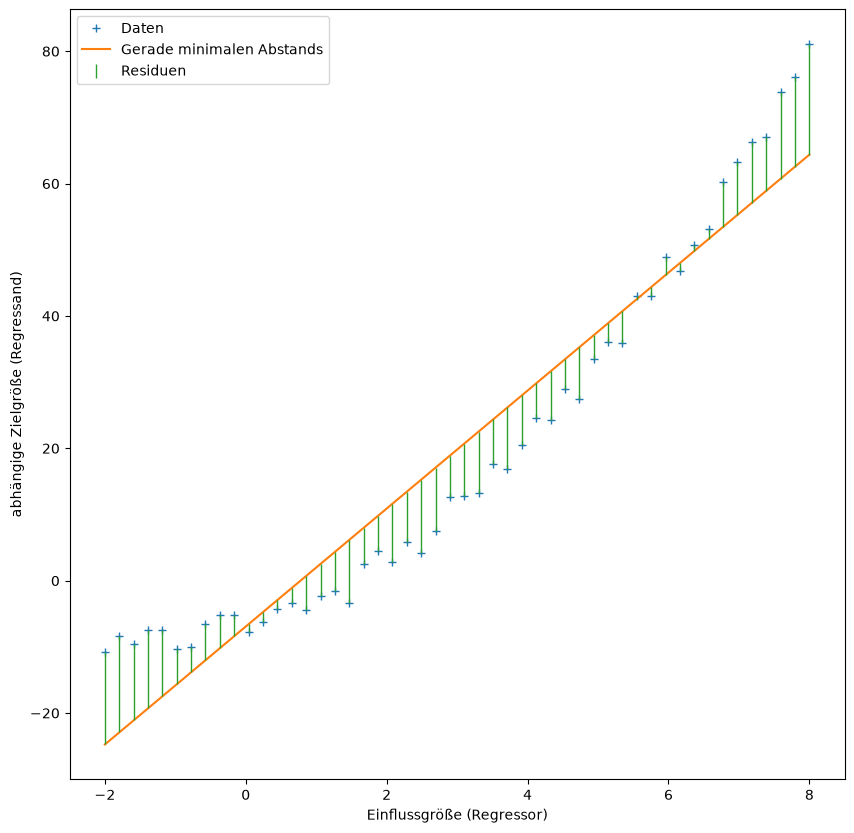

In [5]:
fig, ax = plt.subplots(figsize=(10,10))
ax.plot(x, y, "+", label="Daten")
ax.plot(x, f(x, beta_0, beta_1), label="Gerade minimalen Abstands")
yerr = np.stack((np.maximum(np.zeros_like(y), y - f(x, beta_0, beta_1)),
                 -np.minimum(np.zeros_like(y), y - f(x, beta_0, beta_1))))
ax.errorbar(x, y,
            yerr=yerr,
            linewidth=0, elinewidth=1,
            label="Residuen")
ax.set_xlabel("Einflussgröße (Regressor)")
ax.set_ylabel("abhängige Zielgröße (Regressand)")
ax.legend()
plt.show()

Bitte beachten Sie, dass dies nicht die Richtung maximaler Varianz ist - dabei werden zwar auch Abstände minimiert, aber eben die Abstände der Datenpunkte $(x,y)$ zur Geraden. Bei der linearen Regression werden nicht Abstände der Datenpunkte zur Geraden minimiert, sondern die Residuen, das sind die Abstände entlang der $y$-Achse. Im Plot oben ist das sichtbar: die grünen Striche sind parallel zur $y$-Achse, nicht senkrecht auf der Geraden (was dem Abstand zur Geraden entsprechen würde).

Damit ist auch klar, dass die Regression ein asymmetrisches Verfahren ist, in dem Sinne dass Regressor und Regressand nicht vertauscht werden können, ohne das Modell zu ändern. Bei der Suche nach einer Gerade entlang maximaler Varianz sind $x$- und $y$-Koordinaten gleichberechtigt und die Lösung invariant unter Drehungen.

## Lineare Regression

```{admonition} Definition
Eine Regression der Form $Y_i = f(X_i, w) + \epsilon_i$ mit $f(x, w) = w^T x$ heißt **lineare Regression**. Die Einträge des Vektors $w$ heißen die **Gewichte** (weights) des Modells: $w_j$ sagt, wie stark der Regressor $X_j$ in die Vorhersage eingeht.
```

```{admonition} Definition
Eine Regression der Form $Y_i = f(X_i, w, w_0) + \epsilon_i$ mit

$$f(x, w, w_0) = w^T x + w_0$$

heißt **lineare Regression mit Bias** $w_0$.
```

Die zweite Definition sieht allgemeiner aus, lässt sich aber auf die erste zurückführen. Man hängt an die Regressoren eine konstante Eins an und an die Gewichte den Bias:

$$
X_+ := (1, X_1, \dots, X_k), \qquad w_+ := (w_0, w_1, \dots, w_k), \qquad (w_+)^T X_+ = w^T X + w_0.
$$

Das ist die übliche stillschweigende Konvention: Für $x = (a,b)$ ist dann $f(x,w) = w^T x = (w_0,w_1,w_2)\cdot(1,a,b) = w_0 + w_1 a + w_2 b$. Der $w_0$-Term (zuvor $\beta_0$ bezeichnet) heißt auch **Bias-Term** (Achsenabschnitt). Mit dem Bias eines Schätzers aus dem vorigen Kapitel hat das nichts zu tun; das Wort ist in der Literatur zum maschinellen Lernen doppelt belegt.

```{admonition} Hinweis
Ein Beispiel für so ein Modell mit Bias: Der Preis $Y$ eines Hauses soll aus der Entfernung zum Stadtzentrum $X_1$ und dem Alter $X_2$ vorhergesagt werden,

$$
Y = \beta_1 X_1 + \beta_2 X_2 + \beta_0 + \epsilon.
$$

Genau dieses Modell rechnen wir weiter unten am Melbourne-Datensatz durch.

Beachten Sie die Sprachregelung: In der Informatik und im maschinellen Lernen heißt die Funktion $f(x_1,x_2) = \beta_1 x_1 + \beta_2 x_2 + \beta_0$ „linear“, obwohl sie es im Sinne der linearen Algebra nicht ist — linear ist nur $(x_1,x_2) \mapsto \beta_1 x_1 + \beta_2 x_2$, denn eine lineare Abbildung schickt die Null auf die Null. In der Mathematik heißt $f$ eine *affin-lineare* Funktion. Der $X_+$-Trick von oben ist genau die Übersetzung zwischen beiden Sprechweisen: Die affin-lineare Funktion auf $\mathbb{R}^k$ ist eine lineare Funktion auf $\mathbb{R}^{k+1}$.
```


Eine einfache lineare Regression lässt sich mit Scipy.stats durchführen:

In [6]:
from scipy.stats import linregress

linregress_result = linregress(x, y)
slope, intercept, r, p, se = linregress_result
print("Steigung: %f" % slope)
assert np.isclose(slope, beta_1)
print("Achsenabschnitt: %f" % intercept)
assert np.isclose(intercept, beta_0)
print("Korrelationskoeffizient: %f" % r)
print("p-Wert: %.32f" % p)
print("Standardfehler der Steigung: %f" % se)

Steigung: 8.912806
Achsenabschnitt: -6.929693
Korrelationskoeffizient: 0.959514
p-Wert: 0.00000000000000000000000000046030
Standardfehler der Steigung: 0.377630


Die fünf Rückgabewerte lohnen einen Moment. `slope` ist die Steigung $\beta_1$ und `intercept` der Achsenabschnitt $\beta_0$, also der Bias — das sind die beiden Parameter, die wir haben wollten. `r` ist der Korrelationskoeffizient zwischen $x$ und $y$ (siehe [Kovarianz und Abhängigkeit](kovarianz.md)); sein Quadrat $r^2$ ist der Anteil der Varianz von $y$, den das Modell erklärt, und taucht weiter unten als Bestimmtheitsmaß $R^2$ wieder auf. `p` gehört zu einem Test, den Scipy ungefragt mitgerechnet hat (dazu gleich). Und `se` ist trotz des Namens kein Fehlerquadrat, sondern der **Standardfehler der Steigungsschätzung**: die geschätzte Standardabweichung von `slope`, wenn man das ganze Experiment mit einer neuen Stichprobe wiederholen würde. Als Faustregel liegt die wahre Steigung mit etwa $95\,\%$ Wahrscheinlichkeit im Bereich `slope` $\pm\ 2 \cdot$ `se`.

Scipy hat für uns gleich einen Test durchgeführt, nämlich einen beidseitigen Test mit der Nullhypothese, dass die Steigung `slope` gleich $0$ ist. Da der $p$-Wert deutlich kleiner als $\alpha = 0.05$ ist, verwerfen wir die Hypothese und gehen von einer Steigung $\neq 0$ aus. (Das benutzen wir jetzt einfach, ohne uns eingehender mit statistischen Tests auseinander zu setzen - oder wir ignorieren diesen Teil der Ausgabe von Scipy.stats).

Bevor wir das allgemein aufschreiben, ein Beispiel, bei dem der Trick sofort einleuchtet. Beim Iris-Datensatz liegen Blütenblattlänge $X_1$ und Blütenblattbreite $X_2$ vor, und wir möchten die Kelchblattlänge $Y$ vorhersagen. Nun hängt $Y$ vermutlich weniger von Länge oder Breite einzeln ab als von der *Fläche* des Blütenblatts — und die ist, bis auf einen Formfaktor, das Produkt der beiden. Wir bauen uns also einen neuen Regressor $X_3 := X_1 X_2$ und rechnen damit eine ganz gewöhnliche lineare Regression $Y = w_1 X_3 + w_0 + \epsilon$.

Steigung: 0.150646
Achsenabschnitt: 4.970482
Korrelationskoeffizient: 0.857300
Standardfehler der Steigung: 0.007436


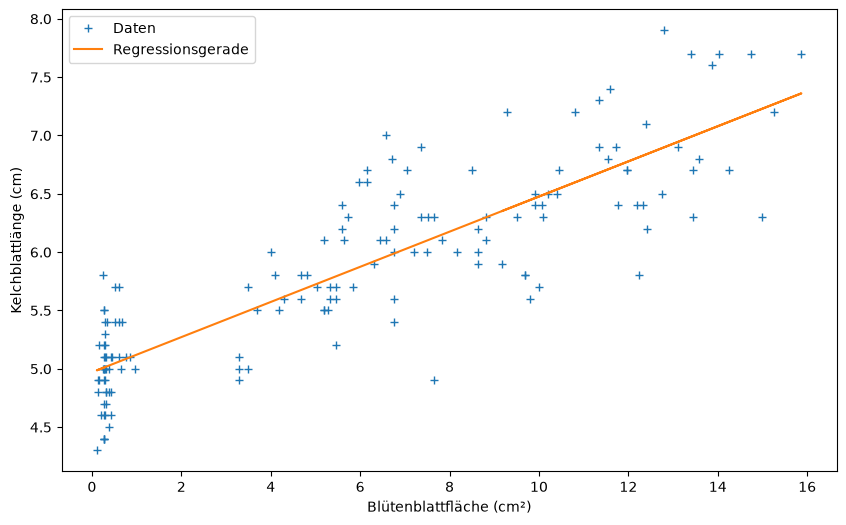

In [7]:
from sklearn import datasets

iris = datasets.load_iris()
x_iris = iris.data
flaeche = x_iris[:, 2] * x_iris[:, 3]   # Bluetenblattlaenge mal -breite
kelchlaenge = x_iris[:, 0]

ergebnis = linregress(flaeche, kelchlaenge)
print("Steigung: %f" % ergebnis.slope)
print("Achsenabschnitt: %f" % ergebnis.intercept)
print("Korrelationskoeffizient: %f" % ergebnis.rvalue)
print("Standardfehler der Steigung: %f" % ergebnis.stderr)

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(flaeche, kelchlaenge, "+", label="Daten")
ax.plot(flaeche, ergebnis.intercept + ergebnis.slope * flaeche, label="Regressionsgerade")
ax.set_xlabel("Blütenblattfläche (cm²)")
ax.set_ylabel("Kelchblattlänge (cm)")
ax.legend()
plt.show()

Wir haben hier nichts anderes getan, als vor der Regression die Funktion $\phi(X_1, X_2) := X_1 X_2$ auf die Regressoren anzuwenden. Das Modell bleibt linear — in den Gewichten $w$, und auf die kommt es an.

Zum Vergleich: Mit der Blütenblattlänge allein kommt man auf $r = 0{,}872$, also auf etwas mehr als mit der Fläche. Eine Basisfunktionserweiterung ist eben nicht automatisch der bessere Regressor, nur weil sie komplizierter ist — sie ist eine Hypothese über die Daten, und ob sie hilft, ist eine empirische Frage. Solche Vorverarbeitungen haben einen eigenen Namen.

```{admonition} Definition
Wenn eine Regressorvariable die Form $\phi(X_i)$ hat, für $\phi$ eine beliebige Funktion mit passendem Definitionsbereich, dann nennt man dies immer noch eine **lineare Regression mit Regressor $X_i$ und Basisfunktionserweiterung**.
```

Damit ist bei einer linearen Regression also nur eins linear: die Funktion $f$ in den Variablen $w$. So können wir das zuvor stillschweigende Ersetzen von $x$ durch $(1,x)$ auch als Basisfunktionserweiterung auffassen, mit $\phi(x) = (1,x)$.

Da die lineare Regressionsanalyse sehr einfach durchzuführen ist, wird die zentrale Frage bei der linearen Regression die Aufstellung des Modells, insbesondere der Basisfunktion anhand von Daten.

Man nennt den Fall $w = (w_0, w_1)$ eine **einfache lineare Regression** und den allgemeineren Fall dann eine **multiple lineare Regression**, weil dabei dann eine multivariate unabhängige Variable $X$ als Regressor verwendet wird. Die lineare Regression von Scipy.stats kann nur eine einfache lineare Regression!

Darum betrachten wir nun die multilineare Regression mit Scikit-learn:

```{admonition} Achtung: Begriffe anderswo
:class: warning
Die Wörter dieses Kapitels werden außerhalb oft enger gebraucht, als wir sie hier definiert haben. Drei Verengungen begegnen Ihnen regelmäßig:

1. **Regression vs. Klassifikation.** Bei uns ist Klassifikation ein Spezialfall der Regression (die Zielgröße ist dann eben kategorial). Verbreitet ist dagegen die Sprechweise „Regression = stetige Zielgröße, Klassifikation = diskrete Zielgröße“, und Bibliotheken sind meist danach sortiert — in Scikit-Learn stehen `LinearRegression` und `LogisticRegression` in verschiedenen Ecken der Dokumentation, obwohl beide Regressionen im hiesigen Sinn sind.
2. **Regression = lineare Regression.** Bei uns ist eine Regression irgendein Modell mit einer Funktion $f$. Wer „Regression“ ohne Zusatz sagt, meint aber oft die lineare.
3. **Regression = Regressionsgerade.** Regression funktioniert in beliebig vielen Dimensionen; gemeint ist trotzdem häufig der eindimensionale Fall, dessen Ergebnis sich als Gerade zeichnen lässt.

Keine dieser Verengungen ist falsch, man muss nur wissen, in welcher Bedeutung das Wort gerade steht. Im Zweifel hilft die Frage: Was ist die Zielgröße, und wie viele Regressoren gibt es?
```

In [8]:
from sklearn.linear_model import LinearRegression

# first look at linear, to compare with the above:
linear_regressor = LinearRegression()
linear_regressor.fit(x.reshape(-1, 1), y)
Y_pred = linear_regressor.predict(x.reshape(-1, 1)) 

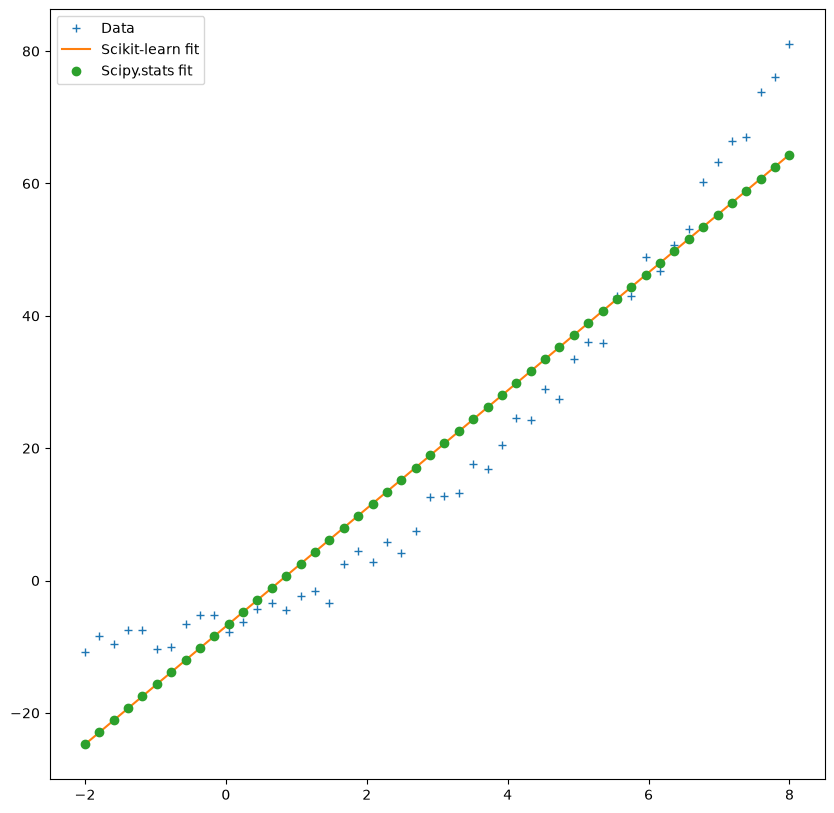

In [9]:
fig, ax = plt.subplots(figsize=(10,10))
ax.plot(x, y, "+", label="Data")
ax.plot(x, Y_pred, label="Scikit-learn fit")
ax.plot(x, f(x, beta_0, beta_1), "o", label="Scipy.stats fit")
ax.legend()
plt.show()

Aus der Scikit-learn-Dokumentation:

`sklearn.linear_model.LinearRegression`
>
> From the implementation point of view, this is just plain Ordinary Least Squares (scipy.linalg.lstsq) or Non Negative Least Squares (scipy.optimize.nnls) wrapped as a predictor object.

So gesehen ist Scikit-learn nicht 'besser' als Scipy, sondern einfach ein Layer oben drauf.

```{admonition} Beispiel
Die Nutzung der Basisfunktion $\phi(x) = (1,x,x^2,x^3,\dots,x^d)$ mit $d > 0$ nennt man **polynomiale Regression**.
Konkret für $d=2$ bedeutet das, dass $f(x,w) = w_0 + w_1x + w_2x^2$ ist. Wir sehen nochmal deutlich: $f$ ist linear in $w$, nicht in $x$.
```

Ein Problem bei der Wahl einer Basisfunktion für ein Regressionsmodell ist das Overfitten. Wenn zu viele Parameter verfügbar sind, lassen sich die Daten zwar sehr gut fitten, aber das Modell verallgemeinert nicht gut. Konkret prüfen lässt sich das durch einen Fit auf einen Trainingsdatensatz, der dann auf einem Testdatensatz evaluiert wird.

```{admonition} Beispiel
Wir betrachten das Overfitten in Abhängigkeit vom Parameter $d$ der polynomialen Regression, auf dem gleichen Datensatz wie zuvor im Beispiel mit einer Regressionsgeraden (der Fall $d=1$).
```

In [10]:
# define basis function class
def phi(x, d):
    return np.dstack([np.power(x, i) for i in range(d+1)]).squeeze()

def plot_regression(x, y, Y_pred, ax, x_test=None, y_test=None):
    ax.plot(x, y, "+", label="Daten")
    if(x_test is None):
        x_test = x
    ax.plot(x_test, Y_pred, label="Modell")
    if(y_test is None):
        y_test = y
    yerr = np.stack(( np.maximum(np.zeros_like(y_test), y_test - Y_pred),
                     -np.minimum(np.zeros_like(y_test), y_test - Y_pred)))
    ax.errorbar(x_test, y_test,
                yerr=yerr,
                linewidth=0, elinewidth=1,
                label="Residuen")
    ax.set_xlabel("Einflussgröße (Regressor)")
    ax.set_ylabel("abhängige Zielgröße (Regressand)")
    ax.legend()
    return ax

def poly_regression_plot(x, y, d):
    # perform regression analysis:
    transformed_x = phi(x, d)

    linear_regressor = LinearRegression()
    linear_regressor.fit(transformed_x, y)
    Y_pred = linear_regressor.predict(transformed_x)
    
    fig, ax = plt.subplots(figsize=(10,10))
    plot_regression(x, y, Y_pred, ax).\
      set_title("Polynomiale Regression von Grad %d" % d)
    plt.show()

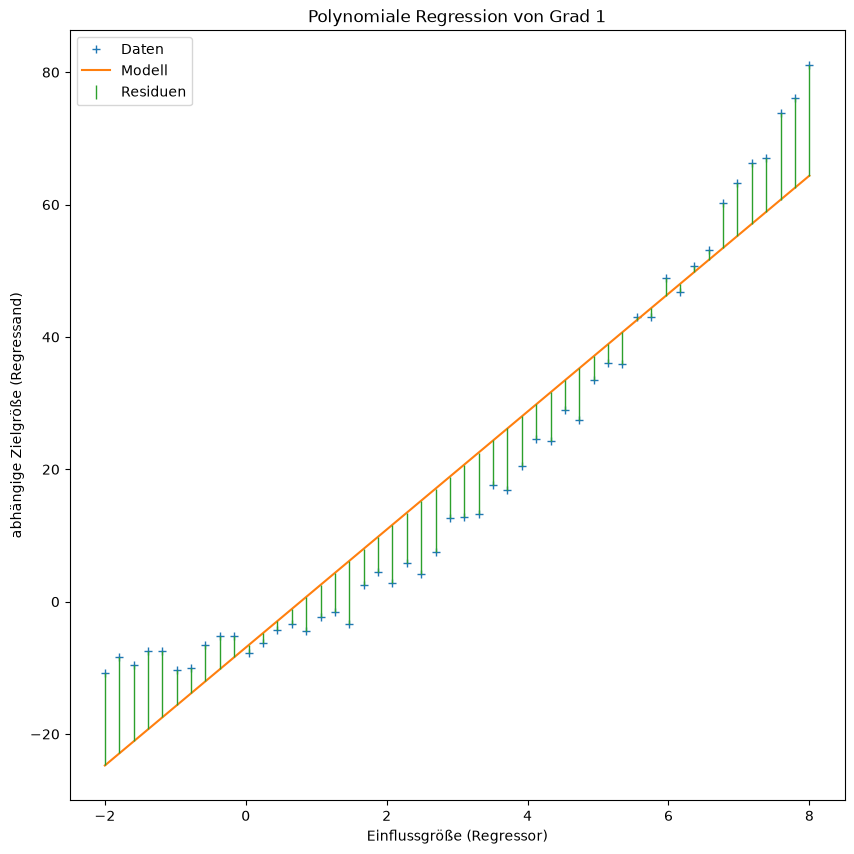

In [11]:
poly_regression_plot(x, y, 1)

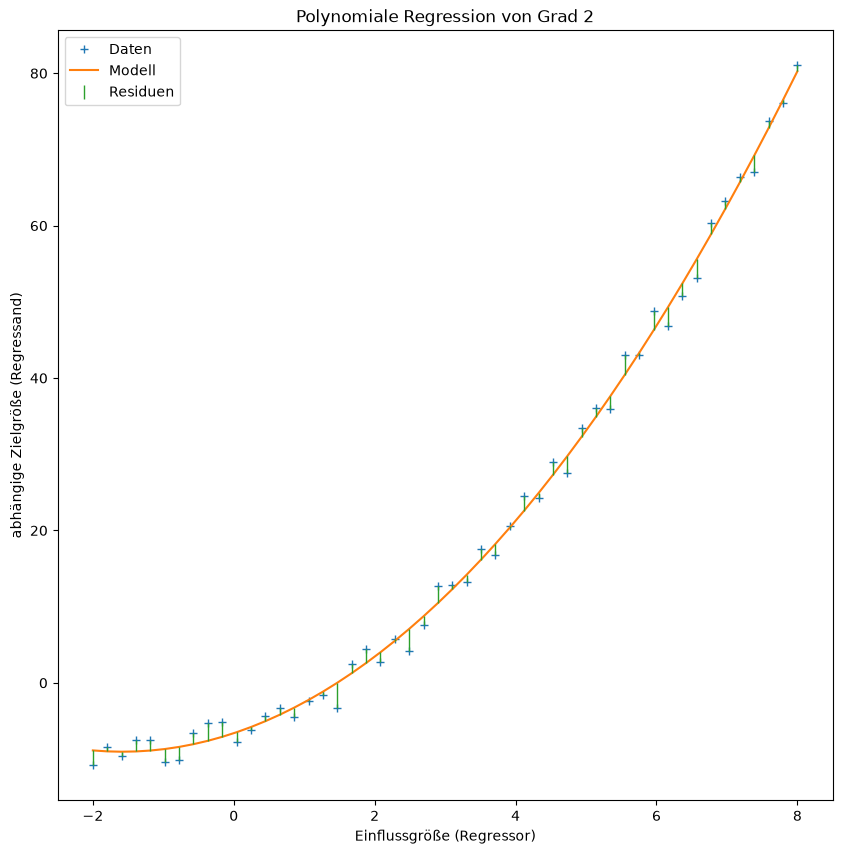

In [12]:
poly_regression_plot(x, y, 2)

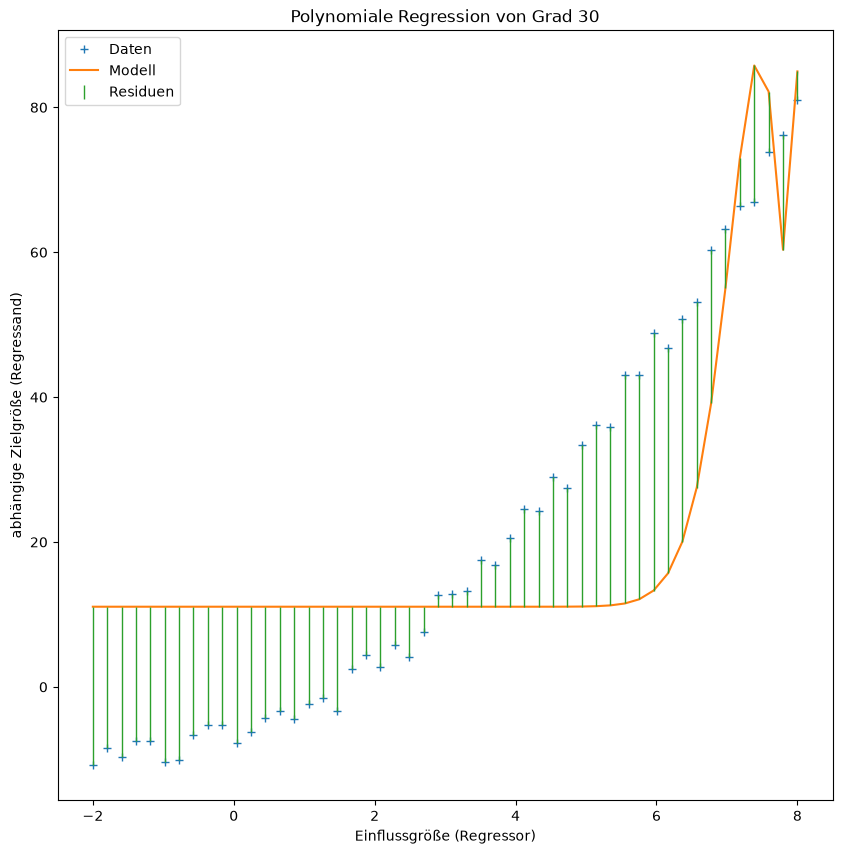

In [13]:
poly_regression_plot(x, y, 30)

Man kann ein lineares Regressionsmodell auch formulieren als

$$
P(y|X, \theta) = \mathcal{N}(w^T X, \sigma^2)
$$

bzw. mit Basisfunktionserweiterung

$$
P(y|X, \theta) = \mathcal{N}(w^T \phi(X), \sigma^2)
$$

Dabei sind $\theta_i$ die Parameter der normalverteilten Fehler $\epsilon_i$.

## Anwendungsbeispiel

Wir betrachten den [Melbourne Housing Market Datensatz von Anthony Pino](https://www.kaggle.com/datasets/anthonypino/melbourne-housing-market). Er steht unter CC BY-NC-SA 4.0 und ist damit von der Lizenz dieses Skripts ausgenommen: Weiterverwendung nur nicht-kommerziell und unter denselben Bedingungen.

Zum Einstieg putzen wir die Daten etwas.

In [14]:
import pandas as pd

df = pd.read_csv("Melbourne_housing_FULL.csv")
print(df.shape)
print(df.columns)

(34857, 21)
Index(['Suburb', 'Address', 'Rooms', 'Type', 'Price', 'Method', 'SellerG',
       'Date', 'Distance', 'Postcode', 'Bedroom2', 'Bathroom', 'Car',
       'Landsize', 'BuildingArea', 'YearBuilt', 'CouncilArea', 'Lattitude',
       'Longtitude', 'Regionname', 'Propertycount'],
      dtype='str')


In [15]:
# don't care about lat, lon here:
df = df.drop(columns=['Lattitude','Longtitude'])

# make Date a date:
df['Date'] = pd.to_datetime(df['Date'], format="%d/%m/%Y")

# Postcode is not really numeric:
df['Postcode'] = df['Postcode'].astype('category')

# make string variables categorical:
string_columns = df.select_dtypes(include=['object', 'string']).columns  # 'string' für pandas >= 3
df[string_columns] = df[string_columns].astype('category')

# Transform year built to age:
df['Age'] = 2017 - df['YearBuilt']
df = df.drop(columns='YearBuilt')

# kill faulty data:
df = df[df['BuildingArea'] != 0]
df = df[df['Age'] < 500]

# remove all suspects with missing data
df = df.dropna()

# remaining numerical variables:
numerical_columns = df.select_dtypes(['float']).columns
print(numerical_columns)

Index(['Price', 'Distance', 'Bedroom2', 'Bathroom', 'Car', 'Landsize',
       'BuildingArea', 'Propertycount', 'Age'],
      dtype='str')


In [16]:
regressor_columns = numerical_columns.drop('Price')
x = df[regressor_columns]
y = df['Price']

from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test \
 = train_test_split(x, y, test_size = .20, random_state=0)

regressor = LinearRegression()
regressor.fit(x_train, y_train)
y_pred = regressor.predict(x_test)

from sklearn.metrics import r2_score
print("R^2 = %f%% der Varianz wird durch das lineare Modell erklärt"
      % (100*r2_score(y_test, y_pred)))

R^2 = 50.355458% der Varianz wird durch das lineare Modell erklärt


Bevor wir die Koeffizienten interpretieren, prüfen wir die Modellannahme, dass die Störgrößen $\epsilon_i$ unabhängig von $x$ um $0$ streuen: Die Residuen $y_i - f(x_i, \beta)$, aufgetragen gegen die Vorhersage, sollten ohne erkennbares Muster um $0$ liegen. Ein Trichter bedeutet, dass die Streuung vom Preis abhängt; eine Krümmung, dass ein linearer Zusammenhang nicht ausreicht.

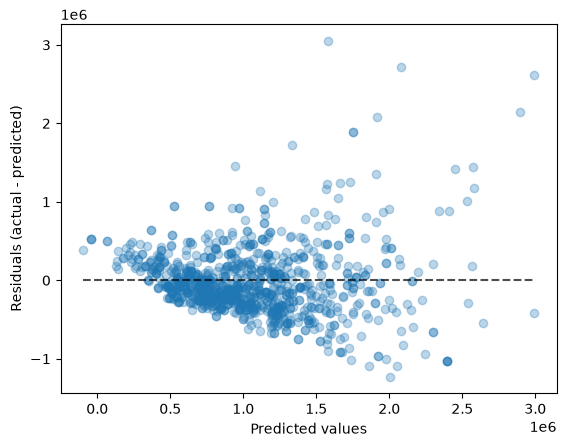

In [17]:
from sklearn.metrics import PredictionErrorDisplay

PredictionErrorDisplay.from_predictions(y_test, y_pred, kind="residual_vs_predicted",
                                        scatter_kwargs={"alpha": 0.3})
plt.show()

```{admonition} Definition
$$
R^2 = 1 - \dfrac{\sum_{i=1}^N {\left( y_i - f(x_i,\beta) \right)}^2}{\sum_{i=1}^N {\left( y_i - \texttt{mean}(y) \right)}^2}
$$

Die Größe $R^2$ wird auch **Bestimmtheitsmaß**, en. **Coefficient of determination** genannt. Im Zähler steht die Residuenquadratsumme des Modells, im Nenner die des besten konstanten Modells $\texttt{mean}(y)$; $R^2$ misst also, welchen Anteil der Streuung von $y$ das Modell gegenüber der Konstanten wegerklärt. Für kleinste Quadrate mit Achsenabschnitt ist das auf den Trainingsdaten dasselbe wie $\sum (f(x_i,\beta) - \texttt{mean}(y))^2 / \sum (y_i - \texttt{mean}(y))^2$, der Anteil der „erklärten“ Varianz; auf Testdaten wie oben gilt nur die erste Form, und dort kann $R^2$ auch negativ werden (Kapitel [Modell-Auswahl](model-selection.ipynb)).
```

In [18]:
cdf = pd.DataFrame(data = regressor.coef_,
                   index = regressor_columns,
                   columns = ['Coefficients'])
cdf

,Coefficients
Distance,-27377.550245
Bedroom2,109775.843441
Bathroom,264198.517970
Car,55837.834214
Landsize,23.997980
BuildingArea,2238.496526
Propertycount,-0.688488
Age,6081.670366


Interpretation:

Wenn ein Haus ein Jahr älter ist als ein anderes, ist der assoziierte Preisunterschied ca. $6081$ (australische) Dollar. Wenn ein Haus einen Kilometer näher am Zentrum (das in Melbourne *CBD* heißt) liegt, also eine um $1$ kleinere Distance-Variable hat, ist der assoziierte Preisunterschied ca. $27377$ Dollar.

### Kategoriale Regressoren: One-Hot-Encoding

Beim Putzen der Daten haben wir alle Textspalten zu `category` gemacht — und sie dann stillschweigend
aus dem Modell gelassen, denn `numerical_columns` enthält nur die `float`-Spalten. Dabei dürfte
`Type` (h = Haus, u = Wohnung/*unit*, t = Reihenhaus/*townhouse*) etwas über den Preis sagen.

Einfach $h = 1$, $u = 2$, $t = 3$ zu setzen wäre falsch: `Type` ist nominalskaliert, eine Reihenfolge
und gleiche Abstände gibt es nicht, und die Regression würde mit beidem rechnen (siehe
[Deskriptive Statistik](deskriptive-statistik.md), Abschnitt Skalenniveau). Stattdessen bekommt jede
Ausprägung eine eigene $0/1$-Spalte, das **One-Hot-Encoding**; pandas nennt die Spalten *Dummies*.
Eine der Spalten lässt man weg (`drop_first=True`): Wer weder `u` noch `t` ist, ist `h`, und die
weggelassene Ausprägung wird zur *Referenzkategorie*, auf die sich die anderen Koeffizienten beziehen.
Ließe man alle drei Spalten drin, wäre ihre Summe immer $1$ — dieselbe Information wie der
Achsenabschnitt $\beta_0$ — und die Parameter wären nicht mehr eindeutig bestimmt (die *Dummy-Falle*).


In [19]:
dummies = pd.get_dummies(df['Type'], prefix='Type', drop_first=True, dtype=float)
print(dummies.head())

x_onehot = pd.concat([df[regressor_columns], dummies], axis=1)
x_train_oh, x_test_oh, y_train_oh, y_test_oh \
 = train_test_split(x_onehot, y, test_size=.20, random_state=0)

regressor_onehot = LinearRegression().fit(x_train_oh, y_train_oh)
print("R^2 ohne Type: %.1f%%" % (100 * r2_score(y_test, y_pred)))
print("R^2 mit Type:  %.1f%%" % (100 * r2_score(y_test_oh, regressor_onehot.predict(x_test_oh))))

pd.DataFrame(data=regressor_onehot.coef_, index=x_onehot.columns, columns=['Coefficients']).tail(2)


    Type_t  Type_u
2      0.0     0.0
4      0.0     0.0
6      0.0     0.0
11     0.0     0.0
14     0.0     0.0
R^2 ohne Type: 50.4%
R^2 mit Type:  50.7%


,Coefficients
Type_t,-66617.632753
Type_u,-178403.074899


Die beiden neuen Koeffizienten lesen sich als Preisunterschied *gegenüber einem Haus* bei sonst
gleichen Merkmalen: Eine Wohnung mit derselben Fläche, demselben Alter und derselben Entfernung zum
Zentrum ist im Modell rund $178\,000$ Dollar günstiger, ein Reihenhaus rund $67\,000$ Dollar.
Dass $R^2$ dabei kaum steigt, überrascht auf den zweiten Blick nicht: Der größte Teil dessen, was
`Type` über den Preis verrät, steckt schon in `BuildingArea`, `Landsize` und `Bedroom2` — Wohnungen
sind vor allem kleiner. Das Encoding hat den Wert des Merkmals also nicht erfunden, sondern nur
lesbar gemacht.

Ein ordinales Merkmal (etwa ein Zustand „schlecht / mittel / gut“) hätte man dagegen als $1, 2, 3$
kodieren dürfen — dort ist die Ordnung echt, nur die gleichen Abstände sind eine Annahme. Für
nominale Merkmale mit sehr vielen Ausprägungen (hier etwa `Suburb` mit mehreren hundert Vororten)
wird das One-Hot-Encoding unhandlich breit; dann braucht es andere Ideen, die über diese Vorlesung
hinausgehen.

Zum Schluss dieses Anwendungsbeispiels noch zwei Bilder zur linearen Regression in den Variablen Distanz und Alter, erst eine, dann beide:


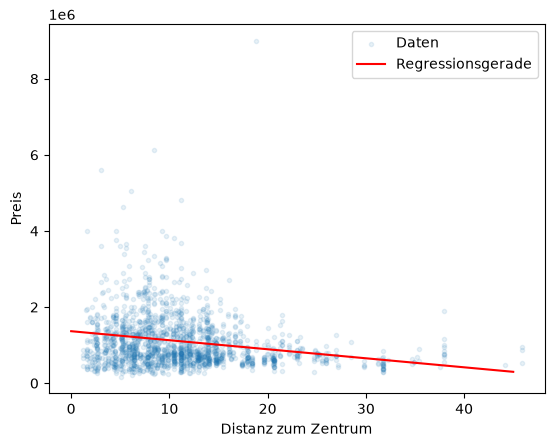

In [20]:
regressor_variable = x_train[["Distance"]]
regressor.fit(regressor_variable, y_train)
y_pred = regressor.predict(regressor_variable)

fig, ax = plt.subplots()
ax.scatter(x_test["Distance"], y_test,
           marker='.', alpha=0.1,
           label="Daten")
xs = np.arange(np.max(x_test["Distance"]))
ys = regressor.coef_[0]*xs + regressor.intercept_
ax.plot(xs, ys, color='red', label="Regressionsgerade")
ax.set_xlabel("Distanz zum Zentrum")
ax.set_ylabel("Preis")
ax.legend()
plt.show()

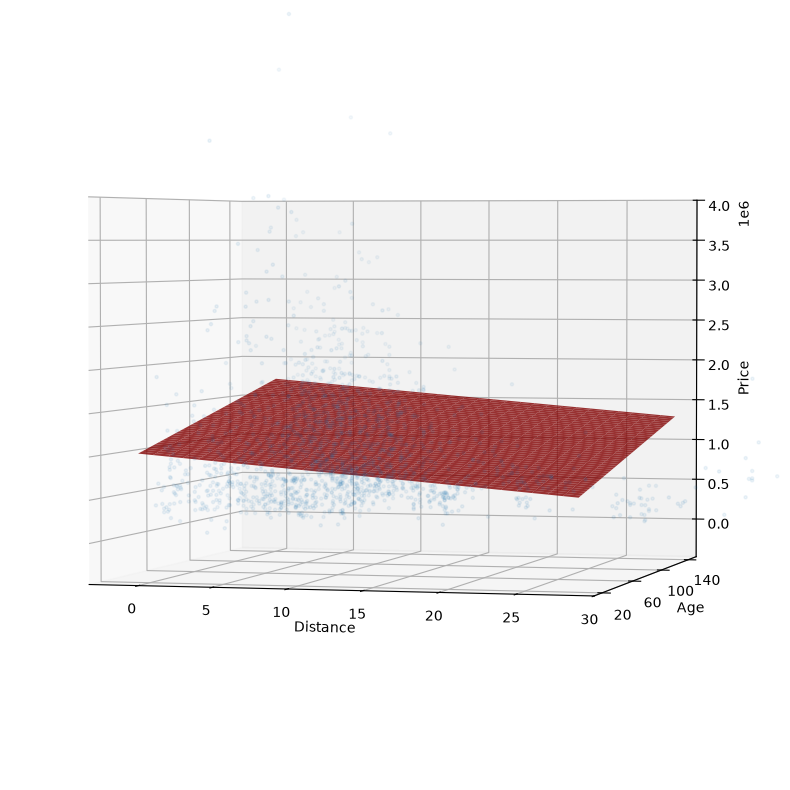

In [21]:
regressor_variable = x_train[["Distance", "Age"]]
regressor.fit(regressor_variable, y_train)
y_pred = regressor.predict(regressor_variable)

from mpl_toolkits.mplot3d import Axes3D

xs = np.arange(30)
ys = np.arange(10, np.max(x_test["Age"]))
xs, ys = np.meshgrid(xs, ys)
zs =   xs*regressor.coef_[0] \
     + ys*regressor.coef_[1] \
     + regressor.intercept_

fig = plt.figure(figsize=(10,10))
ax = fig.add_subplot(111,projection='3d')
ax.plot_surface(xs, ys, zs,
                alpha=0.8, color='red')
ax.scatter(x_test["Distance"], x_test["Age"], y_test,
           marker='.', alpha=0.3)
ax.set_zlim3d(zmax=4000000)
ax.set_xlim3d(xmax=30)
ax.set_ylim3d(ymin=10)
ax.set_xlabel("Distance")
ax.set_ylabel("Age")
ax.set_zlabel("Price")
ax.set_yticks([20,60,100,140])
ax.view_init(elev=2., azim=-75)
plt.show()

So wie diese Daten aussehen, wäre hier auch polynomiale Regression hilfreich. Wir basteln eine Pipeline zur Berechnung der polynomialen Regression.

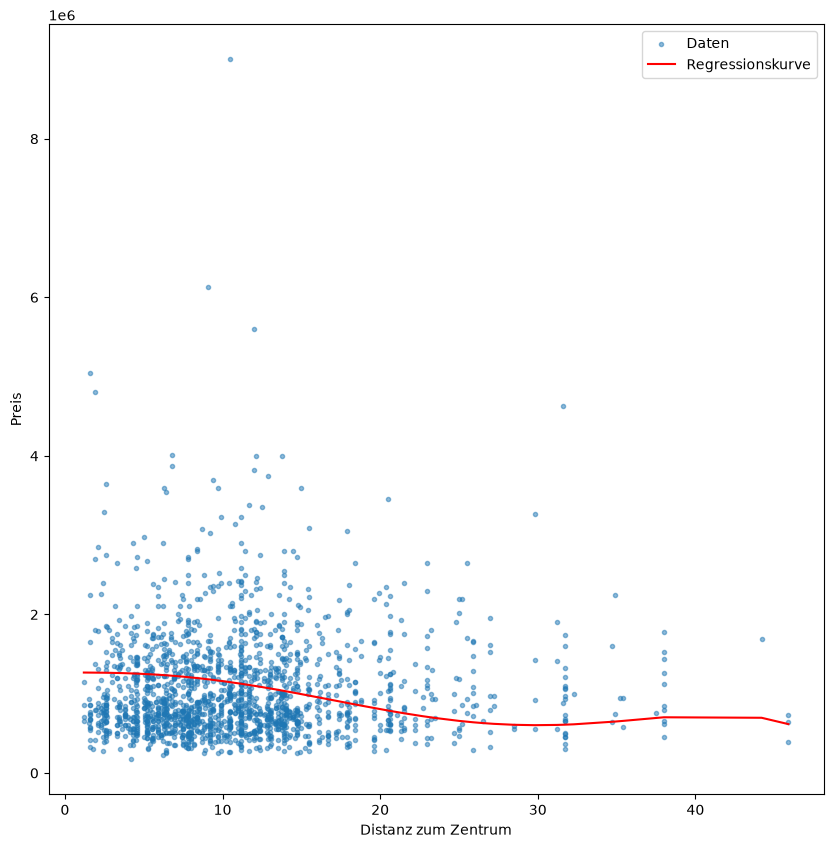

In [22]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

degree = 5

polyreg = make_pipeline(PolynomialFeatures(degree), LinearRegression())
polyreg.fit(x_train[["Distance"]], y_train)
# for plotting purposes, sort:
x_test = x_test.sort_values("Distance")
y_pred = polyreg.predict(x_test[["Distance"]])

fig, ax = plt.subplots(figsize=(10, 10))
ax.scatter(x_test["Distance"], y_test,
           marker='.', alpha=0.5,
           label="Daten")
ax.plot(x_test["Distance"], y_pred,
        color='red', label="Regressionskurve")
ax.set_xlabel("Distanz zum Zentrum")
ax.set_ylabel("Preis")
ax.legend()
plt.show()

## Regularisierung

Wenn man nur wenige Stützstellen in den Trainingsdaten hat, neigt man umso leichter zum Overfitten. Wir schauen uns das in einigen Beispielen an:

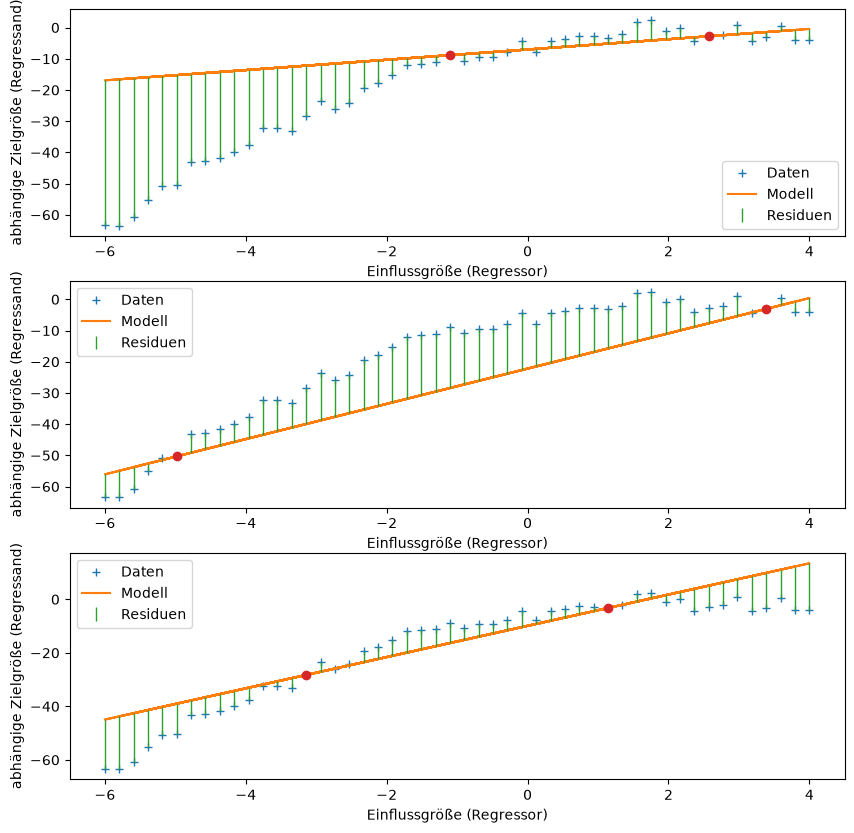

In [23]:
# generate new synthetic data:
np.random.seed(123)
x = np.linspace(-6, 4)
y = -x**2 + 4*x - 5 + np.random.uniform(-4, 4, size=x.shape)

def plot_from_small_training(ax, random_state, model=LinearRegression()):    
    # simulate having very few training data:
    x_train, x_test, y_train, y_test \
     = train_test_split(x, y, test_size = .95,
                        random_state=random_state)

    regressor = model
    regressor.fit(x_train.reshape(-1, 1), y_train)
    y_pred = regressor.predict(x_test.reshape(-1, 1))

    plot_regression(x, y, y_pred, ax, x_test, y_test)
    ax.plot(x_train, y_train, "o")

fig, axs = plt.subplots(3, 1, figsize=(10,10))
plot_from_small_training(axs[0], 3)
plot_from_small_training(axs[1], 4)
plot_from_small_training(axs[2], 5)
plt.show()

Der Trick der Regularisierung besteht nun darin, nicht *zu* gut auf die Trainingsdaten zu fitten.

Die **L2-Regularisierung**, auch als **Ridge-Regression** bekannt, besteht darin, als zusätzliches Optimierungsziel bei der Suche nach einem besten Fit für das Regressionsproblem einen Strafterm $P = \alpha \sum_{i=1}^n \beta_i^2$ zu minimieren.
Dabei ist $\alpha$ ein freier Parameter, der die Stärke der Strafe einstellt.

Der Name L2 kommt daher, dass $P$ das Quadrat der L2-Norm ist.

Dieselbe Idee, große Modellgewichte zu bestrafen, heißt im Deep Learning *weight decay* (Vorlesung *Einführung in Deep Learning*).

Es gibt auch die **L1-Regularisierung** bei der man statt $\beta_i^2$ den Summanden $|\beta_i|$ verwendet, das entspricht der L1-Norm. Man spricht auch von **Lasso-Regularisierung**.

![L1 and L2 balls, image by Wikipedia User Nicoguaro, CC BY 4.0](images/L1_and_L2_balls.svg.png)

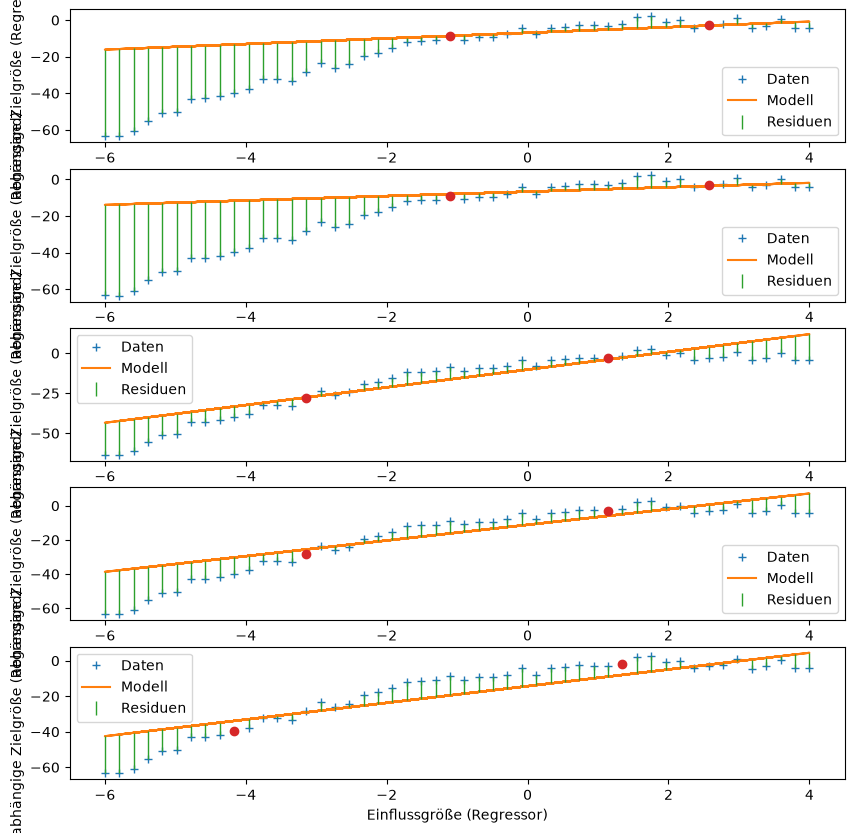

In [24]:
from sklearn.linear_model import Ridge

fig, axs = plt.subplots(5, 1, figsize=(10,10))
plot_from_small_training(axs[0], 3, model=Ridge(alpha=0.5))
plot_from_small_training(axs[1], 3, model=Ridge(alpha=2.5))
plot_from_small_training(axs[2], 5, model=Ridge(alpha=0.5))
plot_from_small_training(axs[3], 5, model=Ridge(alpha=2.5))
plot_from_small_training(axs[4], 10, model=Ridge(alpha=7))
plt.show()

Der praktische Unterschied zwischen L1 und L2: Die L1-Strafe setzt Koeffizienten *exakt* auf $0$ (das sind die Ecken des L1-Balls in der Abbildung), sie wählt also Regressoren aus. Mit den Polynomtermen $x, x^2, \dots, x^8$ als Regressoren für die synthetischen Daten von oben sieht man das direkt:

In [25]:
from sklearn.linear_model import Lasso
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline

def poly_fit(model):
    pipe = make_pipeline(PolynomialFeatures(degree=8, include_bias=False),
                         StandardScaler(), model)
    return pipe.fit(x.reshape(-1, 1), y)[-1]   # das angepasste Modell am Ende der Pipeline

np.set_printoptions(precision=2, suppress=True)
ridge = poly_fit(Ridge(alpha=1.0))
lasso = poly_fit(Lasso(alpha=0.5))
print("Ridge-Koeffizienten:", ridge.coef_)
print("Lasso-Koeffizienten:", lasso.coef_)
print("Bei Lasso exakt 0:", np.sum(lasso.coef_ == 0), "von", len(lasso.coef_), "Koeffizienten")

Ridge-Koeffizienten: [10.6  -7.56  2.39 -1.92 -0.35  0.04 -0.72  0.36]
Lasso-Koeffizienten: [11.34 -8.76  0.71 -0.    0.   -0.    0.   -0.  ]
Bei Lasso exakt 0: 5 von 8 Koeffizienten


## Zusammenfassung

Eine Regression ist ein Modell $Y = f(X,\beta) + \epsilon$; *linear* heißt linear in den Parametern, weshalb Basisfunktionen und One-Hot-Spalten das Modell nicht verlassen. Die Methode der kleinsten Quadrate liefert $\beta_1 = \operatorname{Cov}(x,y)/\sigma^2(x)$ und ist Maximum Likelihood bei normalverteilten Störgrößen; Residuenplots prüfen diese Annahme. Regularisierung (Ridge, Lasso) bestraft große Koeffizienten und ist das Mittel gegen Overfitting bei zu vielen Basisfunktionen.

Video: [Crash Course Statistics Regression](https://www.youtube.com/watch?v=WWqE7YHR4Jc)